# Train on $D^2_{min}$

For earlier attempts, we trained rearrangement as a binary classification
problem; either particles rearrange, or they don't. We used a cutoff in
$D^2_{min}$ to determine if particles rearranged. This approach worked, but it
had some quirks. 

In [1]:
import torch
from torch.utils.data import DataLoader, Dataset
from torch import nn
from sklearn.preprocessing import StandardScaler


import numpy as np
import polars as pl
import pandas as pd
import gsd.hoomd
import schmeud
import schmeud._schmeud as schmeud_rs
from schmeud._schmeud import statics
from schmeud import ml
# from tqdm import tqdm

import glob
import os
import pathlib
import pickle
import signac
import freud
from numba import njit

from dataclasses import dataclass
from collections import defaultdict

import matplotlib.pyplot as plt
from scipy import stats
from typing import Union

# from dataset import GlassDataset
from model import AutoEncoder, LongAutoEncoder, DeepSet
from tqdm.notebook import tqdm

In [2]:
from monk import workflow, utils

In [3]:
cwd = pathlib.Path(os.getcwd())
parent = cwd.parent.parent.parent / "config.yaml"
config = workflow.get_config(parent.as_posix())
local = cwd / "config.yaml"
local_config = workflow.get_any_yaml(local.as_posix())
DATA = local_config["data"]
PROJECT: signac.Project = signac.get_project(root=config['root'])
parent, config, local_config

(PosixPath('/home/ian/Projects/work/monk/workflows/2d-osc-shear/config.yaml'),
 {'root': '/media/ian/Data2/monk/2d-osc-shear',
  'origin': '/media/ian/Data2/monk/2d-esl'},
 {'data': '/media/ian/Poppy/improved-nn/qle-v3'})

In [4]:
PROJECT.find_job_ids()

/tmp/ipykernel_1293995/2594364462.py:1: DeprecatedWarning: find_job_ids is deprecated as of 1.3 and will be removed in 2.0. Use find_jobs() instead, then access ids with job.id.Replicate the original behavior with [job.id for job in project.find_jobs()]
  PROJECT.find_job_ids()


['634e14bc75836df75158fb15f379d8bb',
 '7ec2f6aca035e69077eab24383a21cb6',
 'cfa1e4c0007fd65d020f809715a6f0b4',
 'ecce68c50e28a33684826f28780bf6e9',
 '1d0fe2ba44a6f635f5504dcbcee0ebc9',
 '1083a2a09eec2c6cf215ebc7a9706cac',
 '09d3dccc56f1fa9330b57901cd232ab7',
 '6976a7c10ada4159010403f8027f3ea5',
 '9158e73b2e4c9fd1a565e1e5d1bc3af5',
 'c6d7afd0de62bfa16d05da47815227eb',
 'bf92a185d043ce3ef666e05e427c7e76',
 'a8f2c249ed85533b56b0729b7ab96d18']

In [5]:
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")
device

device(type='cpu')

In [6]:
val_data = ["1083a2a09eec2c6cf215ebc7a9706cac", "bf92a185d043ce3ef666e05e427c7e76"]
test_data = ["6976a7c10ada4159010403f8027f3ea5", "a8f2c249ed85533b56b0729b7ab96d18"]

In [7]:
# test HTL = 6976a7c10ada4159010403f8027f3ea5
# test ESL = a8f2c249ed85533b56b0729b7ab96d18
# val HTL = 1083a2a09eec2c6cf215ebc7a9706cac
# val ESL = bf92a185d043ce3ef666e05e427c7e76
# rest are training set

In [55]:
def get_desciptor(file):
    frame = int(utils.extract_between(file, "frame-", ".npz"))
    cycle = (frame + 1)/40
    max_shear = float(utils.extract_between(file, "shear-", "_period"))
    period = float(utils.extract_between(file, "period-", "_temp"))
    temp = float(utils.extract_between(file, "temp-", "_frame"))
    return {"frame": frame, "cycle": cycle, "max_shear": max_shear, "period": period, "temp": temp}

def get_prep(file, jobs):
    id = file.split("/")[-2]
    return jobs[id].sp["prep"]

class GlassDataset(Dataset):
    def __init__(self, path = None, glob="dataset_max-shear_*", mode="train", filter=None):
        if path is None:
            path = DATA

        path = pathlib.Path(path)
        job_ids = list(PROJECT.find_job_ids())

        if mode == "train":
            job_ids = [id for id in job_ids if id not in val_data + test_data]
        elif mode == "val":
            job_ids = val_data
        elif mode == "test":
            job_ids = test_data
        elif mode in job_ids:
            job_ids = [mode]
        else:
            raise ValueError(f"mode {mode} not recognized")
        
        self._jobs = {id: PROJECT.open_job(id=id) for id in job_ids}
        self._path = path.resolve()
        files = []
        descs = []
        for id in job_ids:
            files += list((self._path / id).glob(glob))
            descs += [get_desciptor(file.as_posix()) for file in files]

        if filter is not None:
            pair = [(file, desc) for file, desc in zip(files, descs) if filter(desc)]
            files, descs = zip(*pair)
        self._files = files
        self._d2min_files = [file.as_posix().replace("qle-v3", "d2min-v1").replace(".npz", ".parquet") for file in files]
        self._desc = descs
        for file, desc in zip(self._files, self._desc):
            id = file.as_posix().split("/")[-2]
            desc["prep"] = get_prep(file.as_posix(), self._jobs)
            desc["id"] = id
        self._len = len(self._files)

    def __len__(self):
        return self._len
    
    def get_info(self, idx):
        file = self._d2min_files[idx]
        desc = self._desc[idx]
        data = pd.read_parquet(file)
        return data, desc
    
    def __getitem__(self, idx):
        file = self._d2min_files[idx]
        qle_file = self._files[idx]
        desc = self._desc[idx]
        data = pd.read_parquet(file)
        data_qle = np.load(qle_file)
        # sfs = np.vstack(data["sfs"].to_numpy())

        # shape = sfs.shape
        evecs = data_qle["evecs"][:67, :, :]
        evals = data_qle["evals"][:67]
        # evals[evals < 1e-4] = 0
        X = np.zeros((evecs.shape[1], evecs.shape[0], 5), dtype=np.float32)
        # strain = data["strain"].to_numpy()
        # X[:, 0] = desc["max_shear"]
        # X[:, 1] = desc["temp"]
        # X[:, 2] = data["soft"].to_numpy()
        # X[:, 3:] = sfs
        X[:, :, 0] = evecs[:, :, 0].T
        X[:, :, 1] = evecs[:, :, 1].T
        X[:, :, 2] = np.array([evals] * evecs.shape[1])
        X[:, :, 3] = np.linalg.norm(evecs, axis=2).T
        X[:, :, 4] = np.square(X[:, :, 3]/X[:, :, 2])
        # make NANs 0
        X[np.isnan(X)] = 0
        tX = torch.tensor(X, dtype=torch.float32)#.to(device)
        d2min = np.log(data["d2min_irr"].to_numpy())
        ty = torch.tensor(d2min, dtype=torch.float32)#.to(device)
        return ty, tX

class SimpleCustomBatch:
    def __init__(self, data):
        transposed_data = list(zip(*data))
        self.y = torch.stack(transposed_data[0], 0).view(-1, 1)
        self.X = torch.stack(transposed_data[1], 0).view(-1, 67, 5)

    # custom memory pinning method on custom type
    def pin_memory(self):
        self.y = self.y.pin_memory()
        self.X = self.X.pin_memory()
        return self

def collate_wrapper(batch):
    return SimpleCustomBatch(batch)

In [56]:
model = None

In [121]:
filter = lambda x: (x["max_shear"] == 0.01 and x["temp"] <= 1e-2 and x["cycle"] < 2)
dataset = GlassDataset(path=DATA, glob="dataset_max-shear*", mode="train", filter=filter)
test_dataset = GlassDataset(path=DATA, glob="dataset_max-shear*", mode="test", filter=filter)
val_dataset = GlassDataset(path=DATA, glob="dataset_max-shear*", mode="val", filter=filter)

/tmp/ipykernel_1293995/3753697666.py:19: DeprecatedWarning: find_job_ids is deprecated as of 1.3 and will be removed in 2.0. Use find_jobs() instead, then access ids with job.id.Replicate the original behavior with [job.id for job in project.find_jobs()]
  job_ids = list(PROJECT.find_job_ids())


In [122]:
len(dataset), len(test_dataset), len(val_dataset)

(8, 2, 2)

In [123]:
df, desc = dataset.get_info(0)
desc

{'frame': 39,
 'cycle': 1.0,
 'max_shear': 0.01,
 'period': 1000.0,
 'temp': 0.0019836,
 'prep': 'HTL',
 'id': '634e14bc75836df75158fb15f379d8bb'}

In [124]:
for i in range(8):
    _, desc = dataset.get_info(i)
    print(desc)

{'frame': 39, 'cycle': 1.0, 'max_shear': 0.01, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 39, 'cycle': 1.0, 'max_shear': 0.01, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'ESL', 'id': '7ec2f6aca035e69077eab24383a21cb6'}
{'frame': 39, 'cycle': 1.0, 'max_shear': 0.01, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': 'cfa1e4c0007fd65d020f809715a6f0b4'}
{'frame': 39, 'cycle': 1.0, 'max_shear': 0.01, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': 'ecce68c50e28a33684826f28780bf6e9'}
{'frame': 39, 'cycle': 1.0, 'max_shear': 0.01, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'ESL', 'id': '1d0fe2ba44a6f635f5504dcbcee0ebc9'}
{'frame': 39, 'cycle': 1.0, 'max_shear': 0.01, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'ESL', 'id': '09d3dccc56f1fa9330b57901cd232ab7'}
{'frame': 39, 'cycle': 1.0, 'max_shear': 0.01, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '9158e73b2e4c9fd1a565e1e5d1bc3af5'}
{'frame': 39,

In [125]:
df.head()

,frame,strain,id,soft,sfs,soft_rev,sfs_rev,d2min_rev,d2min_left,d2min_right,d2min_irr
0,39,0.01,1,-0.499602,"[0.0, 0.0, 0.0, 0.0, 0.03510948, 0.0, 0.457890...",-0.390092,"[0.0, 0.0, 0.0, 0.0, 0.038349837, 0.0, 0.47929...",0.026514,0.018333,0.001369,0.015773
1,39,0.01,0,-0.802161,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.081867486, 0.0, 0....",-0.773208,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.082979135, 0.0, 0....",0.165409,0.132537,0.001957,0.001335
2,39,0.01,1,-0.618469,"[0.0, 0.0, 0.0, 0.0, 0.07628106, 0.0, 0.768426...",-0.613705,"[0.0, 0.0, 0.0, 0.0, 0.07534532, 0.0, 0.761746...",0.157414,0.131432,0.001241,0.001698
3,39,0.01,0,0.219188,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.004841507, 0.0, 0....",0.248394,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.005260453, 0.0, 0....",0.055076,0.046043,0.000577,0.004430
4,39,0.01,0,0.438543,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.056...",0.476427,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.054...",0.748621,0.651581,0.004294,0.000637


In [126]:
loader = DataLoader(dataset, batch_size=1, shuffle=True, pin_memory=True, collate_fn=collate_wrapper, num_workers=3)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=True, pin_memory=True, collate_fn=collate_wrapper, num_workers=3)

In [127]:
y_scaler = StandardScaler()
X_scaler = StandardScaler()

for idx, sample in enumerate(loader):
    y_scaler.partial_fit(sample.y.numpy())
    X_scaler.partial_fit(sample.X.view(-1, 5).numpy())
    # if idx == 100:
    #     break

In [64]:
sample.X[:, 0]

tensor([[ 9.7178e-11,  4.0004e-10, -1.1820e-05,  4.1168e-10,  1.2130e-09],
        [-1.4669e-09,  1.1699e-09, -1.1820e-05,  1.8763e-09,  2.5197e-08],
        [ 2.4164e-09, -5.0723e-09, -1.1820e-05,  5.6185e-09,  2.2594e-07],
        ...,
        [-6.6919e-10, -8.7673e-10, -1.1820e-05,  1.1029e-09,  8.7067e-09],
        [ 1.4028e-09, -7.5130e-09, -1.1820e-05,  7.6429e-09,  4.1808e-07],
        [ 4.1187e-09, -4.6101e-09, -1.1820e-05,  6.1819e-09,  2.7353e-07]])

In [65]:
sample.X.shape

torch.Size([32768, 67, 5])

In [66]:
if model is not None:
    del model

import gc         # garbage collect library
gc.collect()
torch.cuda.empty_cache() 

In [68]:
import torch

import torch.nn.functional as F
from torch_geometric.nn.aggr import Aggregation, SumAggregation
from torch_geometric.nn.inits import reset
from torch_geometric.nn import MLP
from torch import nn

class MyDeepSet(nn.Module):

    def __init__(self, input_dim, output_dim, inter_dim=128, h_dim=32, n_layers=3):
        """Deep set takes input of shape (batch_size, n, input_dim) and returns output of shape (batch_size, output_dim)
        
        The "n" inputs of the set are passed through an MLP and aggregated using sum.

        The sum is then passed through another MLP to get the output.
        """
        super().__init__()

        self.input_dim = input_dim
        self.inter_dim = inter_dim
        self.output_dim = output_dim
        self.h_dim = h_dim
        self.n_layers = n_layers

        self.n_layers = n_layers

        self.mlp1 = MLP(in_channels=self.input_dim, hidden_channels=h_dim,
                        out_channels=self.inter_dim, num_layers=self.n_layers)
        
        self.mlp2 = MLP(in_channels=self.inter_dim, hidden_channels=h_dim,
                        out_channels=self.output_dim, num_layers=self.n_layers)


    def forward(self, x):
        shape = x.shape
        x = x.view(-1, shape[-1])
        x = self.mlp1(x)
        print(x.shape)
        # sum over middle dimension
        x = x.view(shape[0], shape[1], x.shape[-1])
        x = torch.sum(x, dim=1)
        print(x.shape)
        x = self.mlp2(x)
        print(x.shape)
        return x

In [71]:
model = MyDeepSet(5, 1).to(device)

loss = nn.MSELoss()
# pearson correlation loss function

# def pearson_loss(y_true, y_pred):
#     y_true = y_true - torch.mean(y_true)
#     y_pred = y_pred - torch.mean(y_pred)
#     return 1 -torch.sum(y_true * y_pred) / (torch.sqrt(torch.sum(y_true ** 2)) * torch.sqrt(torch.sum(y_pred ** 2)))

# loss = pearson_loss

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [72]:
postfix = dict(epoch=0, loss=np.nan)
sub_batches = 4
pbar = tqdm(total=len(loader)*sub_batches, postfix=postfix)

losses = []
test_losses = []

# idx = 0
for epoch in range(10):
    postfix["epoch"] = epoch + 1
    for sample in loader:
        X_shape = sample.X.shape
        sample.y[:] = torch.asarray(y_scaler.transform(sample.y.numpy()))
        sample.X[:] = torch.asarray(X_scaler.transform(sample.X.view(-1, X_shape[-1]).numpy())).view(X_shape)
        y = sample.y.to(device)
        X = sample.X.to(device)
        
        for sb in range(sub_batches):
            size = int(y.shape[0]/sub_batches)
            y2 = y[size*sb:size*(sb+1)]
            X2 = X[size*sb:size*(sb+1)]
            optimizer.zero_grad()

            y_hat = model(X2)

            l = loss(y2, y_hat)

            l.backward()

            optimizer.step()

            v = l.item()

            losses.append(v)

            pbar.update(1)
            postfix["loss"] = v
            pbar.set_postfix(postfix)
    
    pbar.reset()

    epoch_tloss = []

    for sample in test_loader:
        X_shape = sample.X.shape
        sample.y[:] = torch.asarray(y_scaler.transform(sample.y.numpy()))
        sample.X[:] = torch.asarray(X_scaler.transform(sample.X.view(-1, X_shape[-1]).numpy())).view(X_shape)
        y = sample.y.to(device)
        X = sample.X.to(device)
        y_hat = model(X)
        l = loss(y, y_hat)
        v = l.item()
        epoch_tloss.append(v)
    tloss = np.mean(epoch_tloss)
    test_losses.append(tloss)
    postfix["test_loss"] = tloss
    pbar.set_postfix(postfix)
        

  0%|          | 0/32 [00:00<?, ?it/s, epoch=0, loss=nan]

torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([8192, 1])
torch.Size([548864, 128])
torch.Size([8192, 128])
torch.Size([81

ValueError: Found array with dim 3. StandardScaler expected <= 2.

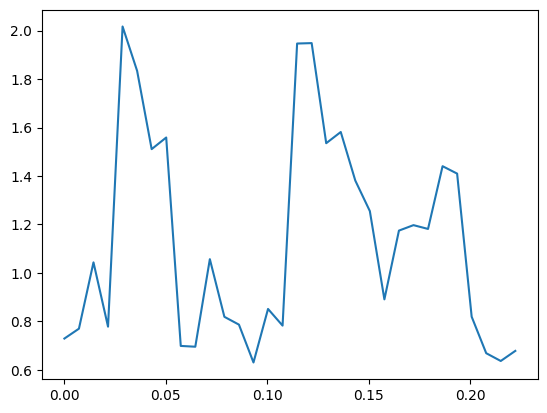

In [75]:
# import windowed average
from scipy.ndimage import uniform_filter1d

plt.plot(np.linspace(0, len(losses)/144, len(losses)), uniform_filter1d(losses, 1))
plt.plot(test_losses)

(array([  1.,   1.,   1.,   3.,   4.,   4.,   6.,   9.,  20.,  11.,  32.,
         30.,  31.,  45.,  54.,  86.,  95.,  93., 101., 146., 136., 168.,
        176., 244., 237., 248., 283., 313., 342., 357., 409., 405., 418.,
        443., 463., 469., 521., 493., 497., 580., 547., 540., 585., 594.,
        594., 582., 593., 621., 641., 607., 604., 573., 577., 577., 562.,
        573., 558., 542., 614., 589., 560., 579., 569., 564., 550., 590.,
        593., 602., 525., 521., 541., 559., 511., 571., 509., 533., 483.,
        450., 425., 381., 346., 352., 294., 268., 237., 227., 189., 139.,
        115.,  76.,  76.,  63.,  40.,  33.,  18.,  13.,   7.,   8.,   2.,
          1.]),
 array([-1.72090352e+00, -1.67889917e+00, -1.63689470e+00, -1.59489036e+00,
        -1.55288589e+00, -1.51088154e+00, -1.46887708e+00, -1.42687273e+00,
        -1.38486838e+00, -1.34286392e+00, -1.30085957e+00, -1.25885510e+00,
        -1.21685076e+00, -1.17484629e+00, -1.13284194e+00, -1.09083760e+00,
        -1.048

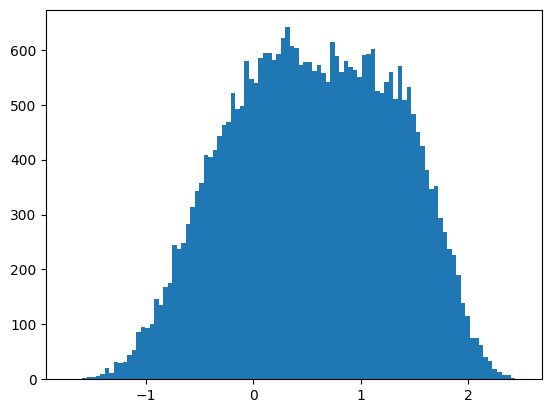

In [76]:
plt.hist(y.detach().cpu().numpy(), bins=100)
# np.xscale('log')

In [128]:
for sample in test_loader:
    X_shape = sample.X.shape
    # sample.y[:] = torch.asarray(y_scaler.transform(sample.y.numpy()))
    # sample.X[:] = torch.asarray(X_scaler.transform(sample.X.view(-1, X_shape[-1]).numpy())).view(X_shape)
    y = sample.y.to(device)
    X = sample.X.to(device)
    y_hat = model(X)
    break

torch.Size([2195456, 128])
torch.Size([32768, 128])
torch.Size([32768, 1])


In [129]:
X_np = X.detach().cpu().numpy()

In [130]:
X_np.shape

(32768, 67, 5)

In [131]:
y_new = np.log(np.sum(np.square(X_np[:, 2:, 3]/ X_np[:, 2:, 2]), axis=1))

In [132]:
X_np[0, :, 2]

array([6.30919430e-07, 1.03469774e-05, 1.76795367e-02, 1.93367321e-02,
       2.02768110e-02, 2.08434928e-02, 3.96813154e-02, 4.02128920e-02,
       4.05417792e-02, 4.17099148e-02, 6.71172217e-02, 7.53738210e-02,
       7.82363862e-02, 7.96173587e-02, 9.14355740e-02, 9.30619314e-02,
       9.46325213e-02, 9.78900045e-02, 9.91427377e-02, 1.01696722e-01,
       1.03732742e-01, 1.05424292e-01, 1.11522451e-01, 1.11947097e-01,
       1.12022296e-01, 1.12589620e-01, 1.33325845e-01, 1.49934471e-01,
       1.55991897e-01, 1.56856298e-01, 1.61075085e-01, 1.65469319e-01,
       1.66391537e-01, 1.74099430e-01, 1.82035789e-01, 1.85822830e-01,
       1.88810751e-01, 1.91839531e-01, 1.95909262e-01, 2.00194612e-01,
       2.02242687e-01, 2.06920758e-01, 2.16969728e-01, 2.18592584e-01,
       2.22131327e-01, 2.23356843e-01, 2.31579378e-01, 2.37165287e-01,
       2.42858335e-01, 2.49571308e-01, 2.50880837e-01, 2.55552322e-01,
       2.60908812e-01, 2.63042867e-01, 2.67487198e-01, 2.80721277e-01,
      

In [133]:
y_new

array([-6.626627, -6.92279 , -8.371603, ..., -8.757529, -8.185482,
       -7.85479 ], dtype=float32)

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([-14.83805943, -14.69468024, -14.55130105, -14.40792186,
        -14.26454267, -14.12116348, -13.9777843 , -13.83440511,
        -13.69102592, -13.54764673, -13.40426754, -13.26088836,
        -13.11750917, -12.97412998, -12.83075079, -12.6873716 ,
        -12.54399241, -12.40061323, -12.25723404, -12.11385485,
        -11.97047566, -11.82709647, -11.68371729, -11.5403381 ,
        -11.39695891, -11.25357972, -11.11020053, -10.96682134,
        -10.82344216, -10.68006297, -10.53668378, -10.39330459,
        -10.2499254 , -10.10654622,  -9.96316703,  -9.81978784,
         -9.67640865,  -9.53302946,  -9.38965027,  -9.24627109,
         -9.1028919 ,  -8.95951271,  -8.81613352,  -8.67275433,
         -8.52937515,  -8.38599596,  -8.2426167

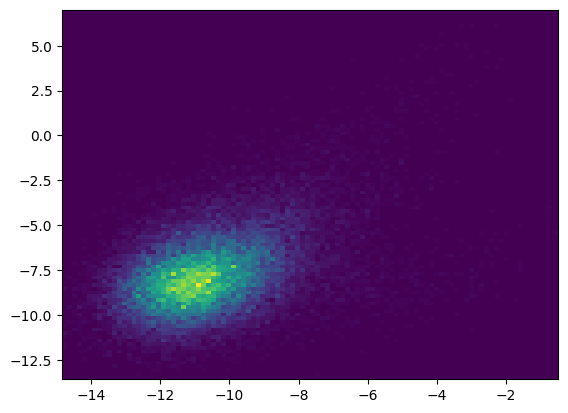

In [134]:
plt.hist2d(y.detach().cpu().numpy().ravel(), y_new, bins=100)

In [135]:
stats.pearsonr(y.detach().cpu().numpy().ravel(), y_new)

PearsonRResult(statistic=0.42518683106569255, pvalue=0.0)

(array([[0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 4.7000e+02, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 5.4740e+03, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 1.2659e+04, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 9.2780e+03, 3.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 3.5040e+03, 6.0000e+00, 1.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 8.7100e+02, 1.0000e+01, 1.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         1.0000e+00, 3.0200e+02, 5.0000e+00, 0.0000e+00, 1.0000e+00],
        [0.0000e+00, 1.0000

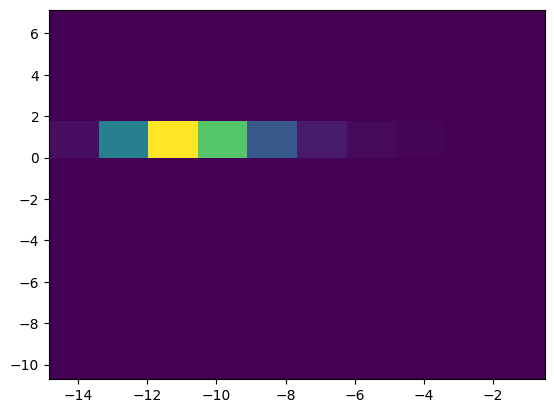

In [136]:
plt.hist2d(y.detach().cpu().numpy().ravel(), y_hat.detach().cpu().numpy().ravel(), bins=10)

In [118]:
import scipy.stats as stats

stats.pearsonr(y.detach().cpu().numpy().flatten(), y_hat.detach().cpu().numpy().flatten())

PearsonRResult(statistic=0.0853050241883703, pvalue=5.576216032244935e-54)

torch.Size([2195456, 128])
torch.Size([32768, 128])
torch.Size([32768, 1])
torch.Size([2195456, 128])
torch.Size([32768, 128])
torch.Size([32768, 1])
torch.Size([2195456, 128])
torch.Size([32768, 128])
torch.Size([32768, 1])
torch.Size([2195456, 128])
torch.Size([32768, 128])
torch.Size([32768, 1])
torch.Size([2195456, 128])
torch.Size([32768, 128])
torch.Size([32768, 1])
torch.Size([2195456, 128])
torch.Size([32768, 128])
torch.Size([32768, 1])
torch.Size([2195456, 128])
torch.Size([32768, 128])
torch.Size([32768, 1])
torch.Size([2195456, 128])
torch.Size([32768, 128])
torch.Size([32768, 1])


(array([1., 0., 2., 0., 1., 2., 1., 0., 0., 1.]),
 array([-0.01826923, -0.00957997, -0.00089072,  0.00779853,  0.01648779,
         0.02517704,  0.0338663 ,  0.04255555,  0.0512448 ,  0.05993406,
         0.06862331]),
 <BarContainer object of 10 artists>)

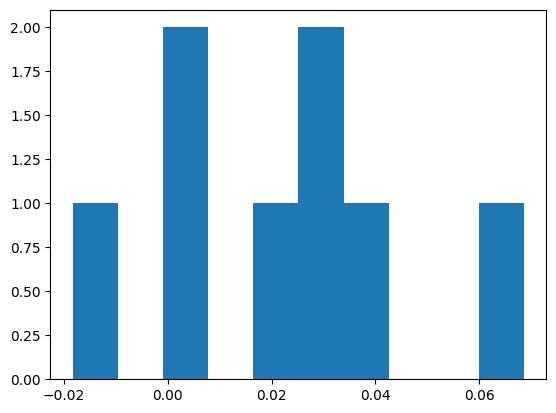

In [83]:
prs = []
for sample in loader:
    X_shape = sample.X.shape
    sample.y[:] = torch.asarray(y_scaler.transform(sample.y.numpy()))
    sample.X[:] = torch.asarray(X_scaler.transform(sample.X.view(-1, X_shape[-1]).numpy())).view(X_shape)
    y = sample.y.to(device)
    X = sample.X.to(device)
    y_hat = model(X)
    pr = stats.pearsonr(y.detach().cpu().numpy().flatten(), y_hat.detach().cpu().numpy().flatten())[0]
    prs.append(pr)
    # break
plt.hist(prs)

In [136]:
prs = []
for sample in test_loader:
    sample.y[:] = torch.asarray(y_scaler.transform(sample.y.numpy()))
    sample.X[:] = torch.asarray(X_scaler.transform(sample.X.numpy()))
    y = sample.y.to(device)
    X = sample.X.to(device)
    y_hat, z = model(X)
    pr = stats.pearsonr(y.detach().cpu().numpy().flatten(), y_hat.detach().cpu().numpy().flatten())[0]
    prs.append(pr)
    # break

(array([3., 1., 6., 4., 4., 2., 8., 4., 3., 1.]),
 array([0.03233757, 0.04436563, 0.05639369, 0.06842176, 0.08044982,
        0.09247789, 0.10450595, 0.11653402, 0.12856208, 0.14059014,
        0.15261821]),
 <BarContainer object of 10 artists>)

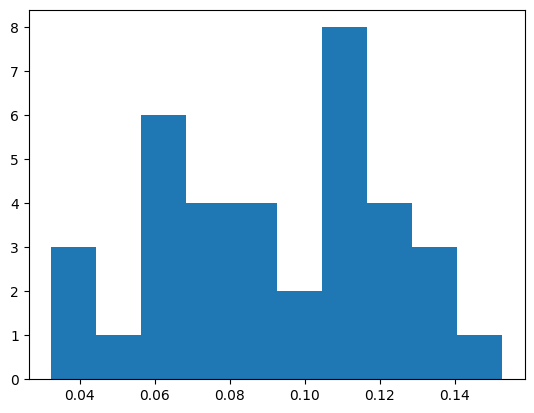

In [137]:
plt.hist(prs)

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([-2.59772539, -2.4925633 , -2.3874012 , -2.2822391 , -2.17707701,
        -2.07191491, -1.96675282, -1.86159072, -1.75642862, -1.65126653,
        -1.54610443, -1.44094234, -1.33578024, -1.23061814, -1.12545605,
        -1.02029395, -0.91513186, -0.80996976, -0.70480766, -0.59964557,
        -0.49448347, -0.38932137, -0.28415928, -0.17899718, -0.07383509,
         0.03132701,  0.13648911,  0.2416512 ,  0.3468133 ,  0.45197539,
         0.55713749,  0.66229959,  0.76746168,  0.87262378,  0.97778587,
         1.08294797,  1.18811007,  1.29327216,  1.39843426,  1.50359635,
         1.60875845,  1.71392055,  1.81908264,  1.92424474,  2.02940683,
         2.13456893,  2.23973103,  2.34489312,  2.45005522,  2.55521731,
         2.66037941])

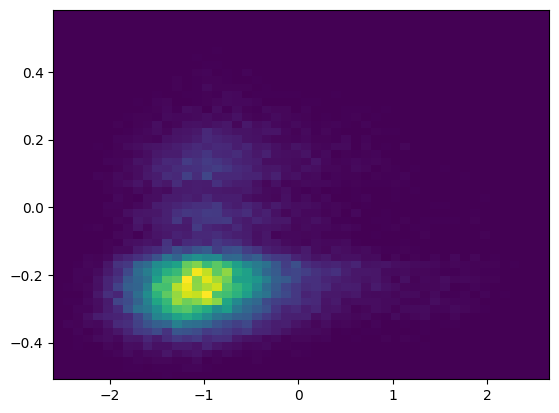

In [138]:
plt.hist2d(y.detach().cpu().numpy().ravel(), y_hat.detach().cpu().numpy().ravel(), bins=50)

In [139]:
import scipy.stats as stats

stats.pearsonr(y.detach().cpu().numpy().flatten(), y_hat.detach().cpu().numpy().flatten())

PearsonRResult(statistic=0.11974724414644103, pvalue=6.323776352322489e-105)